<h1> Gene comparisons nuclei vs cell </h1>

---

In [1]:
import pandas as pd # for excel sheet and data manipulation
import numpy as np
from upsetplot import from_contents, plot, UpSet # for differential expreesion overlap
from matplotlib import pyplot as plt

In [2]:
# load in all datasets
mdx_vs_WT_cell = pd.read_excel("differential expression FAPs/mdxvsWT_cell.xlsx")
TG_vs_WT_cell = pd.read_excel("differential expression FAPs/TGvsWT_cell.xlsx")
TG_vs_mdx_cell = pd.read_excel("differential expression FAPs/TGvsmdx_cell.xlsx")
mdx_vs_WT_nuclei = pd.read_excel("differential expression FAPs/mdxvsWT_nuclei.xlsx")
TG_vs_WT_nuclei = pd.read_excel("differential expression FAPs/TGvsWT_nuclei.xlsx")
TG_vs_mdx_nuclei = pd.read_excel("differential expression FAPs/TGvsmdx_nuclei.xlsx")

In [ ]:
print(mdx_vs_WT_cell.columns)
print(mdx_vs_WT_nuclei.columns)

* same col names, filter pvals_adj < 0.05 and logfoldchanges > 0.25

In [3]:
DEGs_tables = [mdx_vs_WT_cell, TG_vs_WT_cell, TG_vs_mdx_cell, mdx_vs_WT_nuclei, TG_vs_WT_nuclei, TG_vs_mdx_nuclei]

# only first letter capitalized for gene names
for df in DEGs_tables:
    df['names'] = df['names'].str.capitalize()

# filterd on pval and FC
filtered_list = [df[(df['pvals_adj'] < 0.05) & (abs(df['logfoldchanges']) > 0.25)] for df in DEGs_tables]

In [ ]:
for i in range(len(filtered_list)):
    print(filtered_list[i].shape)

In [ ]:
# # name the filtered list with the same names as the original tables
# DEG_tab_names = ["mdx_vs_WT_cell", "TG_vs_WT_cell", "TG_vs_mdx_cell", "mdx_vs_WT_nuclei", "TG_vs_WT_nuclei", "TG_vs_mdx_nuclei"]
# filtered_list_named = dict(zip(DEG_tab_names, filtered_list))

In [4]:
DEGs_UP = [df[df['logfoldchanges'] > 0] for df in filtered_list]
DEGs_down = [df[df['logfoldchanges'] < 0] for df in filtered_list]

In [ ]:
for i in range(len(DEGs_UP)):
    print(DEGs_UP[i].shape)

for i in range(len(DEGs_down)):
    print(DEGs_down[i].shape)

In [5]:
# name these
DEG_tab_names_up = ["mdx_vs_WT_cell_UP", "TG_vs_WT_cell_UP", "TG_vs_mdx_cell_UP", "mdx_vs_WT_nuclei_UP", "TG_vs_WT_nuclei_UP", "TG_vs_mdx_nuclei_UP"]
deg_tab_names_down = ["mdx_vs_WT_cell_DOWN", "TG_vs_WT_cell_DOWN", "TG_vs_mdx_cell_DOWN", "mdx_vs_WT_nuclei_DOWN", "TG_vs_WT_nuclei_DOWN", "TG_vs_mdx_nuclei_DOWN"]
DEGs_UP_named = dict(zip(DEG_tab_names_up, DEGs_UP))
DEGs_down_named = dict(zip(deg_tab_names_down, DEGs_down))

In [6]:
# create sets of gene names (drop NaNs) for each comparison
up_sets = {name: df['names'].dropna().astype(str).unique() for name, df in DEGs_UP_named.items()}
down_sets = {name: df['names'].dropna().astype(str).unique() for name, df in DEGs_down_named.items()}

In [7]:
import matplotlib as mpl
plt.rcParams['font.size'] = 8
mpl.rcParams['figure.dpi'] = 600

e:\mdx single cell and nuclei\.venv\Lib\site-packages\upsetplot\data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


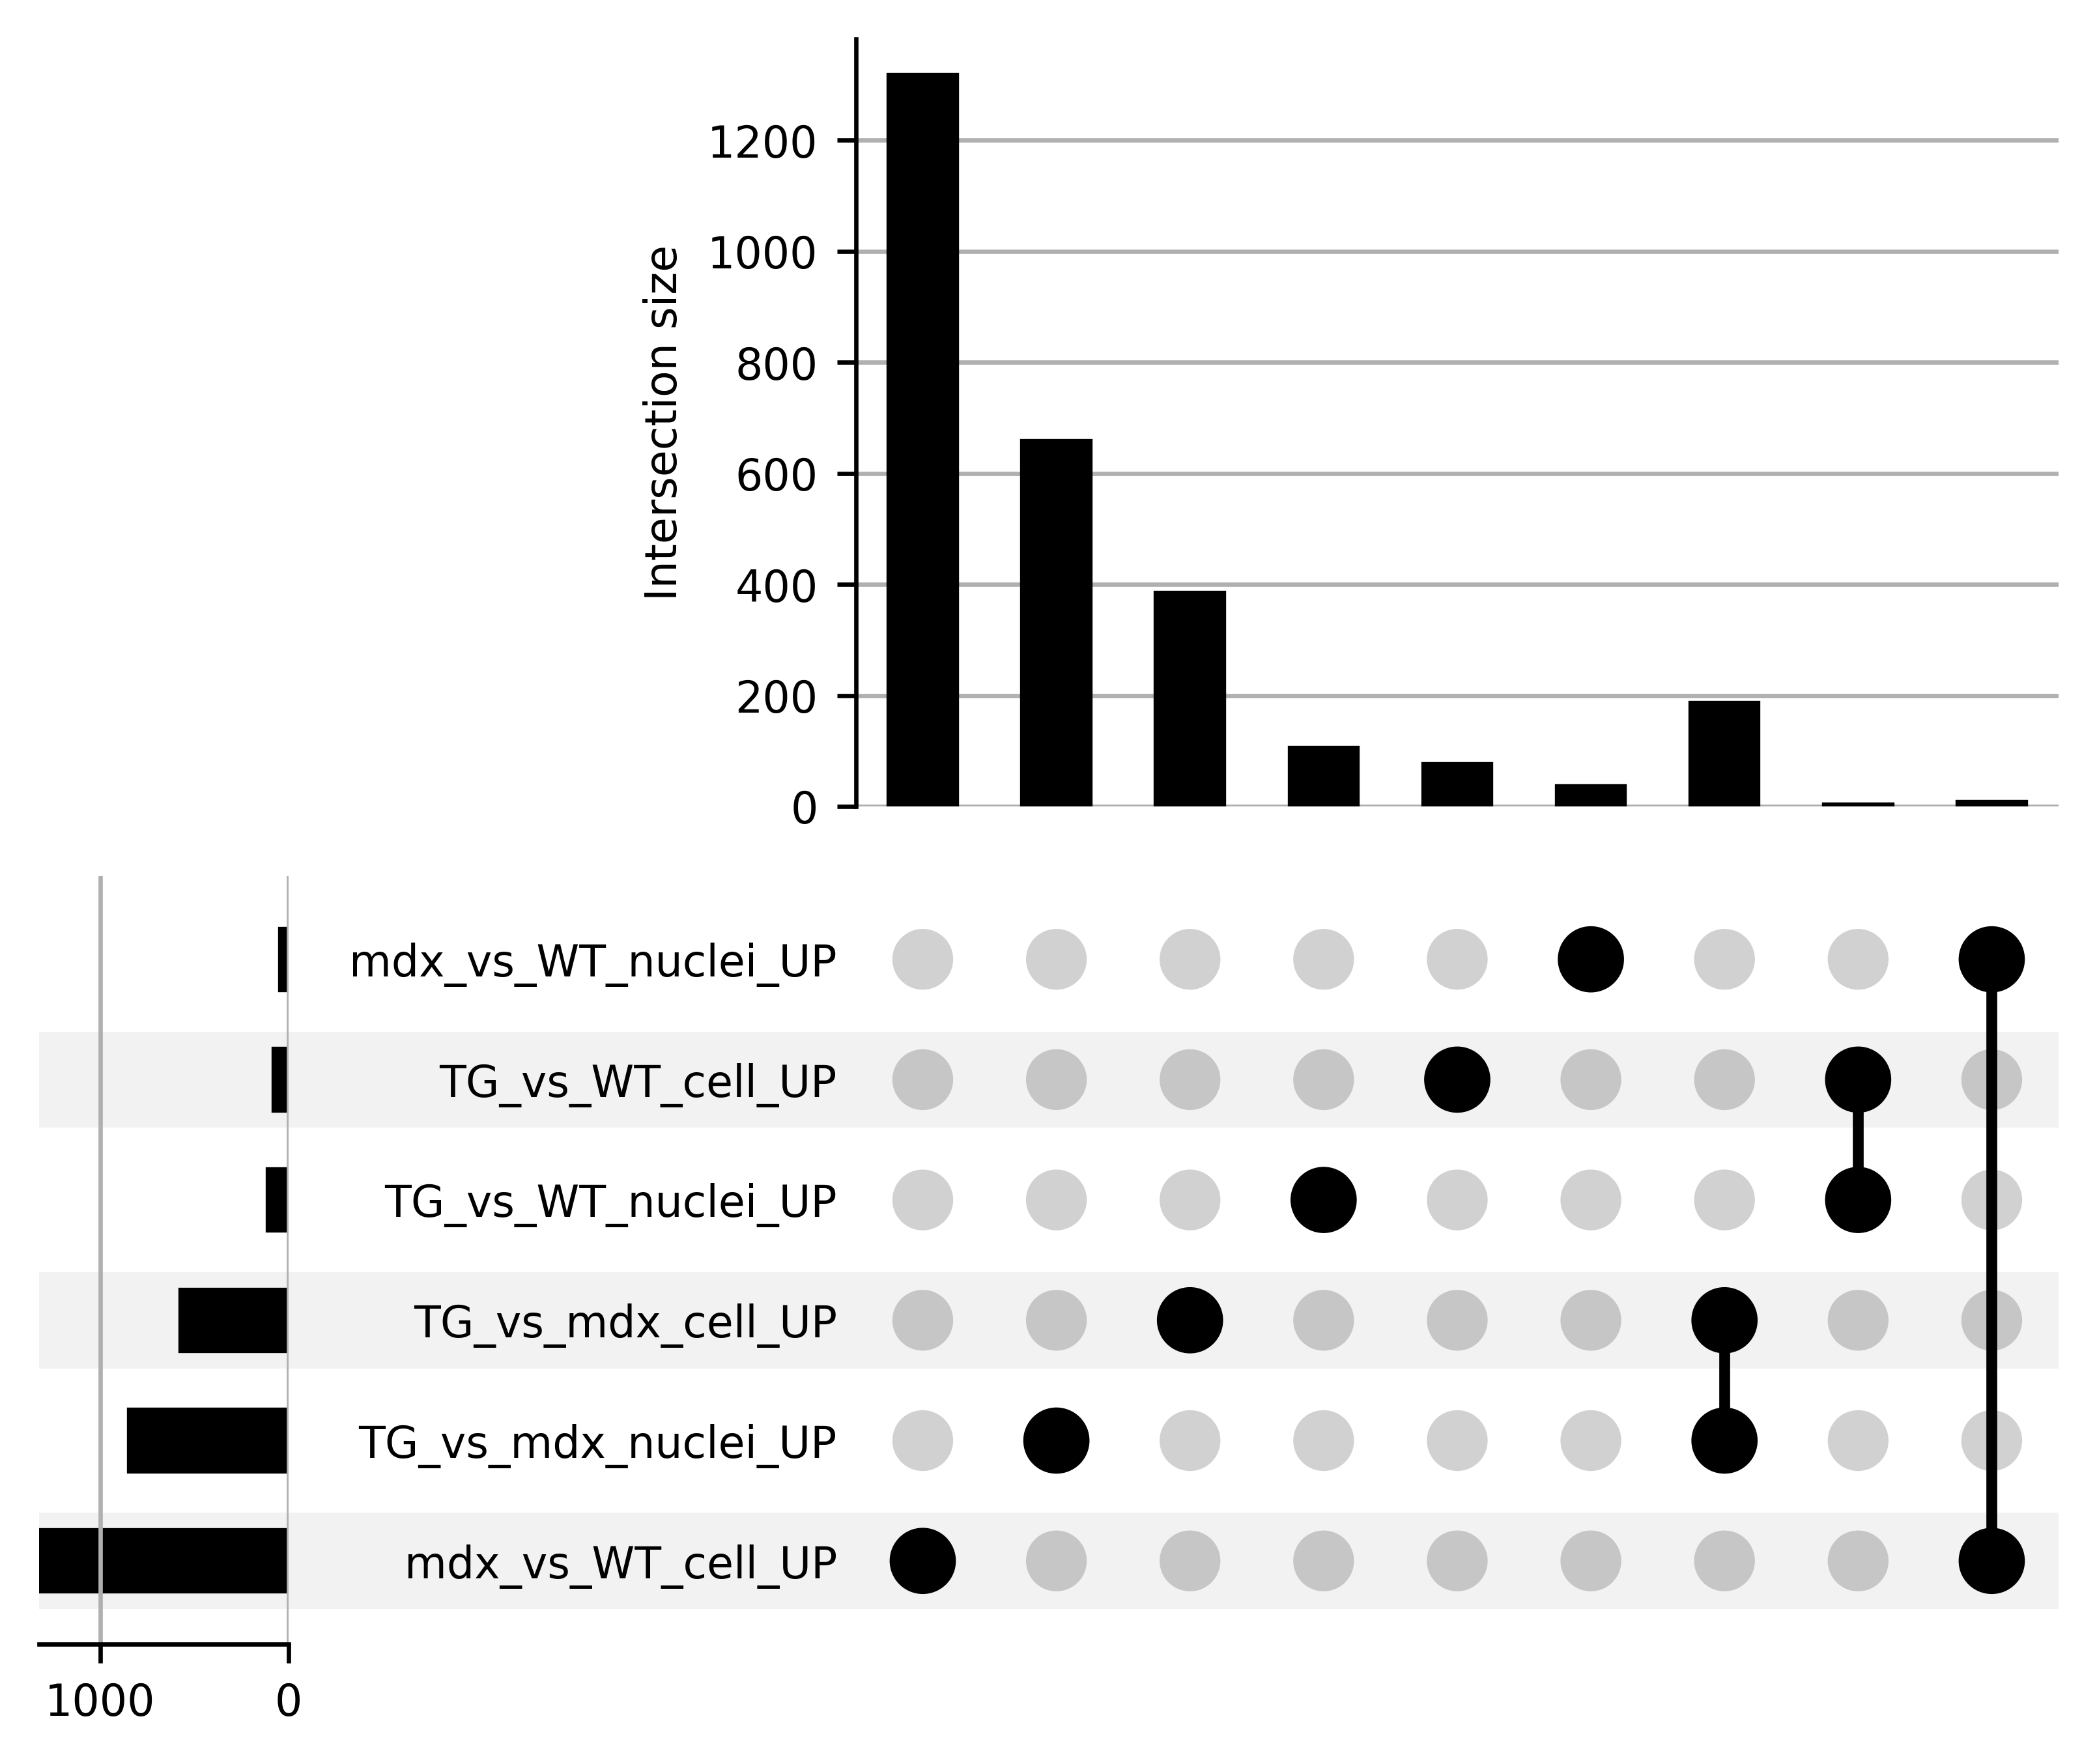

In [8]:
upset_up = from_contents(up_sets)

## only selected intersections
intersections_up = [(True, False, False, False, False, False),
                    (False, True, False, False, False, False),
                    (False, False, True, False, False, False),
                    (False, False, False, True, False, False),
                    (False, False, False, False, True, False),
                    (False, False, False, False, False, True),
                    (True, False, False, True, False, False),
                    (False, True, False, False, True, False),
                    (False, False, True, False, False, True)]

filtered_up = upset_up[upset_up.index.isin(intersections_up)]
up = UpSet(filtered_up)

up.plot()
plt.rcParams['svg.fonttype'] = 'none' # Ensures text is saved as text strings, not paths
plt.savefig("Figures/upset up.svg", format="svg")
plt.show()

In [ ]:
# upset_up = from_contents(up_sets)
# up = UpSet(upset_up)
# up.plot()
# plt.show()

e:\mdx single cell and nuclei\.venv\Lib\site-packages\upsetplot\data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


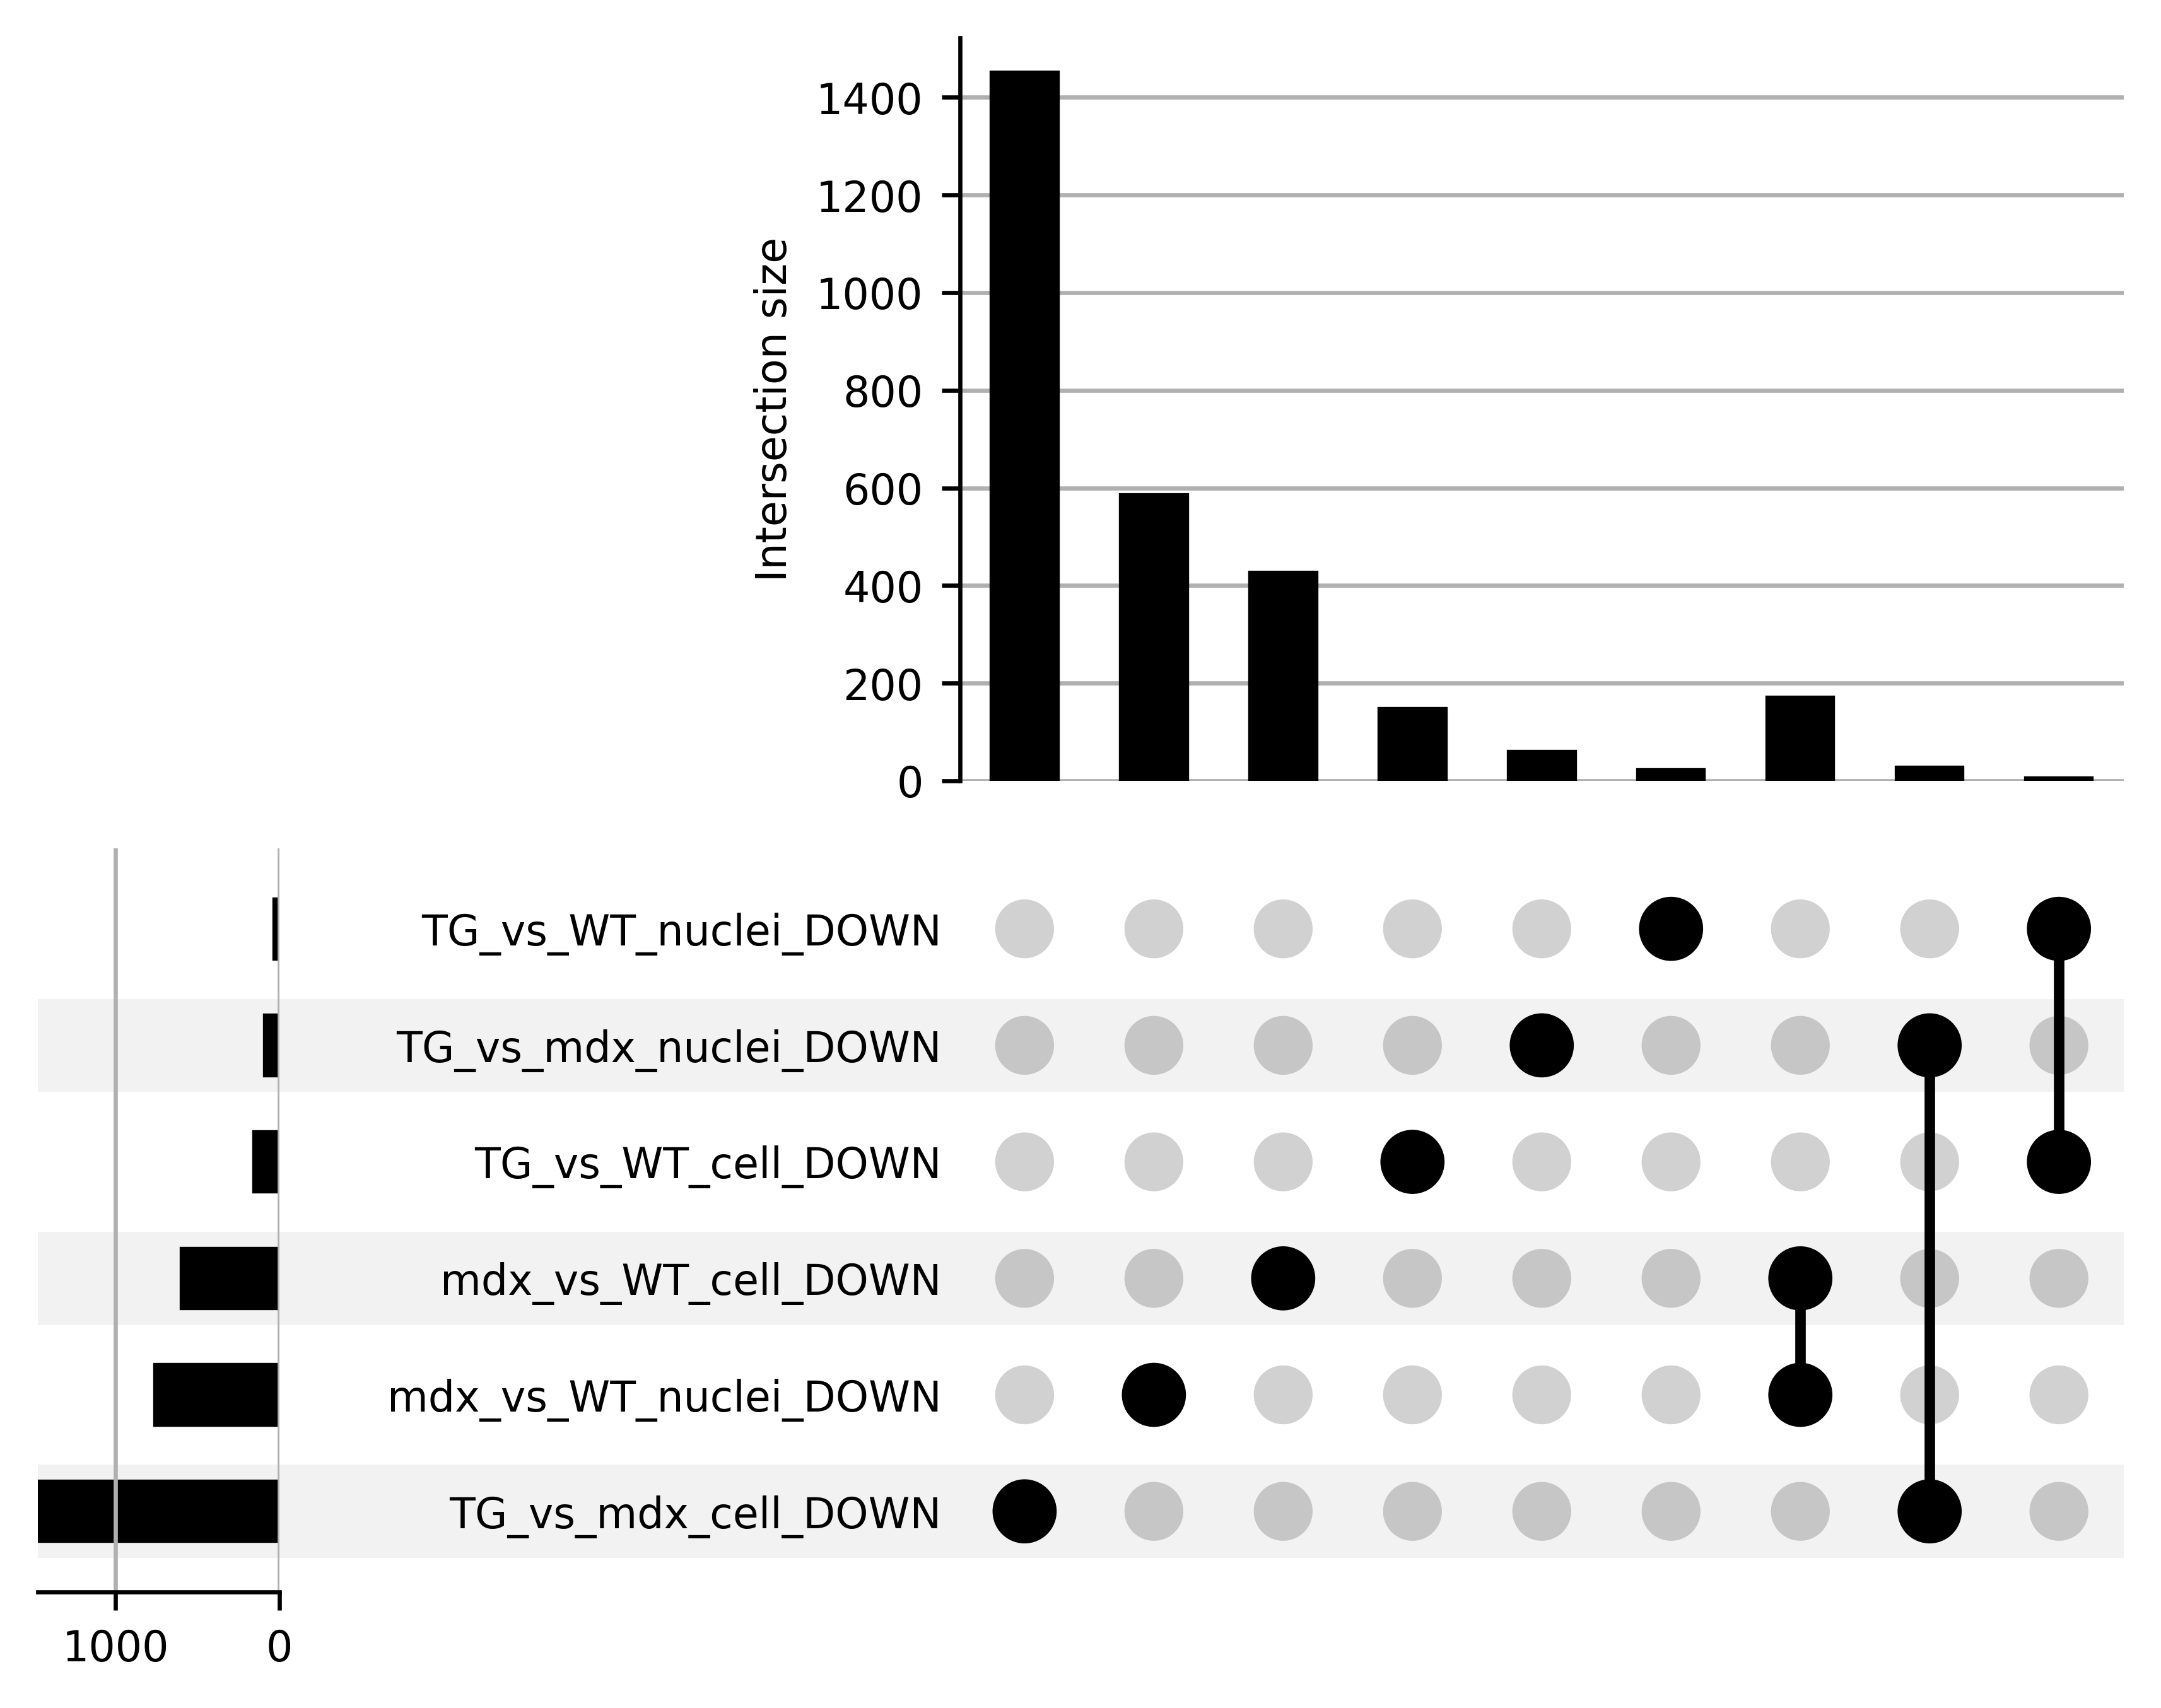

In [9]:
upset_down = from_contents(down_sets)

## only selected intersections
intersections_down = [(True, False, False, False, False, False),
                    (False, True, False, False, False, False),
                    (False, False, True, False, False, False),
                    (False, False, False, True, False, False),
                    (False, False, False, False, True, False),
                    (False, False, False, False, False, True),
                    (True, False, False, True, False, False),
                    (False, True, False, False, True, False),
                    (False, False, True, False, False, True)]

filtered_down = upset_down[upset_down.index.isin(intersections_down)]
down = UpSet(filtered_down)
down.plot()
plt.rcParams['svg.fonttype'] = 'none' # Ensures text is saved as text strings, not paths
plt.savefig("Figures/upset down.svg", format="svg")
plt.show()

In [ ]:
# upset_down = from_contents(down_sets)
# down = UpSet(upset_down)
# down.plot()
# plt.show()

In [ ]:
upset_up.to_excel("upset_up.xlsx")
upset_down.to_excel("upset_down.xlsx")

---
<h1> Compare gene direction </h1>

>which DEGs are detected in the cell vs nuclei?

In [ ]:
mdx_vs_WT_cell = pd.read_excel("differential expression FAPs/mdxvsWT_cell.xlsx")
mdx_vs_WT_nuclei = pd.read_excel("differential expression FAPs/mdxvsWT_nuclei.xlsx")

In [ ]:
mdx_vs_WT_cell['names'] = mdx_vs_WT_cell['names'].str.capitalize()
#print(mdx_vs_WT_cell.head())

In [ ]:
cols_keep = "names"

suffix_cell = "_cell"
suffix_nuclei = "_nuclei"

mdx_vs_WT_cell_named = mdx_vs_WT_cell.rename(columns={
    col: col + suffix_cell for col in mdx_vs_WT_cell.columns if col != cols_keep
    })
mdx_vs_WT_nuclei_named = mdx_vs_WT_nuclei.rename(columns={
    col: col + suffix_nuclei for col in mdx_vs_WT_nuclei.columns if col != cols_keep
    })

both = pd.merge(mdx_vs_WT_cell_named, mdx_vs_WT_nuclei_named, on = "names", how="inner")
print(both)

In [ ]:
print(both.columns)

In [ ]:
both_subset = both[["names", "logfoldchanges_cell", "pvals_adj_cell", 
                    "logfoldchanges_nuclei", "pvals_adj_nuclei"]].copy()

print(both_subset.head())

In [ ]:
# replacing 0 pvalue

both_subset["pvals_adj_cell"] = both_subset["pvals_adj_cell"].replace(
    0, both_subset.loc[both_subset["pvals_adj_cell"] > 0, "pvals_adj_cell"].min()*0.1
    )

both_subset["pvals_adj_nuclei"] = both_subset["pvals_adj_nuclei"].replace(
    0, both_subset.loc[both_subset["pvals_adj_nuclei"] > 0, "pvals_adj_nuclei"].min()*0.1
    )

print(both_subset.head())

In [ ]:
# # -log10 pval * log FC for both
# both_subset["metric_cell"] = both_subset["logfoldchanges_cell"] * -np.log10(both_subset["pvals_adj_cell"])

# both_subset["metric_nuclei"] = both_subset["logfoldchanges_nuclei"] * -np.log10(both_subset["pvals_adj_nuclei"])

# print(both_subset.head())

> don't really need this honestly

In [ ]:
# if both are going in the same "direction"...
both_subset["direction"] = both_subset["logfoldchanges_cell"]*both_subset["logfoldchanges_nuclei"]

# both will be positive when multiplied
both_subset["agreement"] = np.where(both_subset["direction"] > 0, 1, 0)

# add markers
both_subset["signif"] = np.where(
    ## conditions
    (both_subset["agreement"] == 1) & 
      (both_subset["pvals_adj_cell"] < 0.05) &
      (both_subset["pvals_adj_nuclei"] < 0.05), 
      # if all pass
      "*", 
      # if they do not
      "-")

print(both_subset.head())

In [ ]:
both_subset.to_excel("mdx vs WT cell and nuclei DE.xlsx")